In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Load the dataset 
DATA_PATH = 'weatherHistory.csv'  
df = pd.read_csv(DATA_PATH)

# 1. Display first 10 rows
print("--- First 10 Rows ---")
display(df.head(10))

# 2. Check dataset info and missing values
print("\n--- Dataset Info ---")
print(df.info())

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

--- First 10 Rows ---


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.
5,2006-04-01 05:00:00.000 +0200,Partly Cloudy,rain,9.222222,7.111111,0.85,13.9587,258.0,14.9569,0.0,1016.66,Partly cloudy throughout the day.
6,2006-04-01 06:00:00.000 +0200,Partly Cloudy,rain,7.733333,5.522222,0.95,12.3648,259.0,9.9820,0.0,1016.72,Partly cloudy throughout the day.
7,2006-04-01 07:00:00.000 +0200,Partly Cloudy,rain,8.772222,6.527778,0.89,14.1519,260.0,9.9820,0.0,1016.84,Partly cloudy throughout the day.
8,2006-04-01 08:00:00.000 +0200,Partly Cloudy,rain,10.822222,10.822222,0.82,11.3183,259.0,9.9820,0.0,1017.37,Partly cloudy throughout the day.
9,2006-04-01 09:00:00.000 +0200,Partly Cloudy,rain,13.772222,13.772222,0.72,12.5258,279.0,9.9820,0.0,1017.22,Partly cloudy throughout the day.



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB
None

--- Missing Values Count ---
Formatted Da

C:\Users\kitch\AppData\Local\Temp\ipykernel_29708\4288986919.py:6: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df[date_col] = pd.to_datetime(df[date_col])


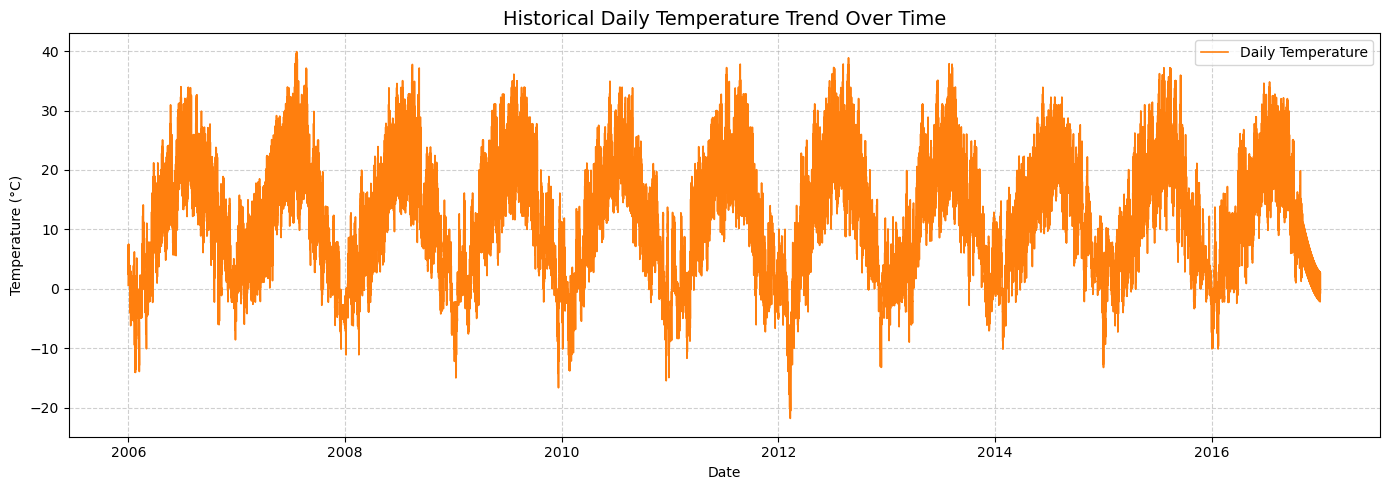

In [2]:
# Identify the date column and temperature column dynamically
date_col = [col for col in df.columns if 'date' in col.lower()][0]
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]

# Convert date column to datetime and sort chronologically
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(by=date_col).reset_index(drop=True)

# Plot temperature trends over time
plt.figure(figsize=(14, 5))
plt.plot(df[date_col], df[temp_col], color='tab:orange', linewidth=1.2, label='Daily Temperature')
plt.title('Historical Daily Temperature Trend Over Time', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [3]:
# 1. Handle missing values via linear interpolation for continuous weather measurements
df_clean = df.copy()
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
df_clean[numeric_cols] = df_clean[numeric_cols].interpolate(method='linear').bfill().ffill()

print("Missing values after cleaning:", df_clean[numeric_cols].isnull().sum().sum())

# 2. Identify target (Temperature) and input weather features
# Ensure temperature is placed at index 0 for easy inverse-transform later
temp_col = [c for c in numeric_cols if 'temp' in c.lower()][0]
other_features = [c for c in numeric_cols if c != temp_col]
feature_cols = [temp_col] + other_features

print(f"Selected Features (Target first): {feature_cols}")
data_values = df_clean[feature_cols].values

# 3. Chronological Split (70% Train, 15% Validation, 15% Test)
total_samples = len(data_values)
train_end = int(total_samples * 0.70)
val_end = int(total_samples * 0.85)

train_raw = data_values[:train_end]
val_raw = data_values[train_end:val_end]
test_raw = data_values[val_end:]

# 4. Normalize values using MinMaxScaler (fit ONLY on training data to avoid leakage)
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_raw)
val_scaled = scaler.transform(val_raw)
test_scaled = scaler.transform(test_raw)

# 5. Create Input Sequences (Past 10 days -> Next day's temperature)
SEQ_LENGTH = 10  # Within the 7-14 days requirement

def create_sequences(dataset, seq_length):
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i : i + seq_length, :])  # All weather features for past 'seq_length' days
        y.append(dataset[i + seq_length, 0])         # Target: next day's temperature (column 0)
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, SEQ_LENGTH)
X_val, y_val = create_sequences(val_scaled, SEQ_LENGTH)
X_test, y_test = create_sequences(test_scaled, SEQ_LENGTH)

print(f"\nSequence Shapes (Samples, Time Steps, Features):")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape},   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")

Missing values after cleaning: 0
Selected Features (Target first): ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover', 'Pressure (millibars)']

Sequence Shapes (Samples, Time Steps, Features):
X_train: (67507, 10, 8), y_train: (67507,)
X_val:   (14458, 10, 8),   y_val:   (14458,)
X_test:  (14458, 10, 8),  y_test:  (14458,)


In [4]:
num_features = X_train.shape[2]

model = keras.Sequential([
    # 1. Input Layer: (sequence_length, num_features)
    layers.Input(shape=(SEQ_LENGTH, num_features)),
    
    # 2. SimpleRNN Layer (64 units)
    layers.SimpleRNN(64, activation='tanh', return_sequences=False),
    
    # 3. Dropout Layer for regularization
    layers.Dropout(0.2),
    
    # 4. Output Layer: 1 unit with linear activation for regression
    layers.Dense(1, activation='linear')
], name="Weather_SimpleRNN")

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

model.summary()

Model: "Weather_SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
BATCH_SIZE = 32
EPOCHS = 60  # Within the 50-100 epochs requirement

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/60
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0085 - mae: 0.0607 - val_loss: 5.5798e-04 - val_mae: 0.0189 - learning_rate: 0.0010
Epoch 2/60
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0017 - mae: 0.0319 - val_loss: 4.1990e-04 - val_mae: 0.0154 - learning_rate: 0.0010
Epoch 3/60
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0010 - mae: 0.0246 - val_loss: 8.1647e-04 - val_mae: 0.0242 - learning_rate: 0.0010
Epoch 4/60
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 8.1296e-04 - mae: 0.0216 - val_loss: 5.7072e-04 - val_mae: 0.0195 - learning_rate: 0.0010
Epoch 5/60
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 7.2054e-04 - mae: 0.0203 - val_loss: 4.6077e-04 - val_mae: 0.0173 - learning_rate: 0.0010
Epoch 6/60
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 6.6624e-04 - mae: 0.0194 - val_loss: 4.9800e-04 - val_mae: 0.0181 - learning_rate: 0.0010
Epoch 7/60
2108/2110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.3979e-04 - mae: 0.0190
Epoch 7: Redu

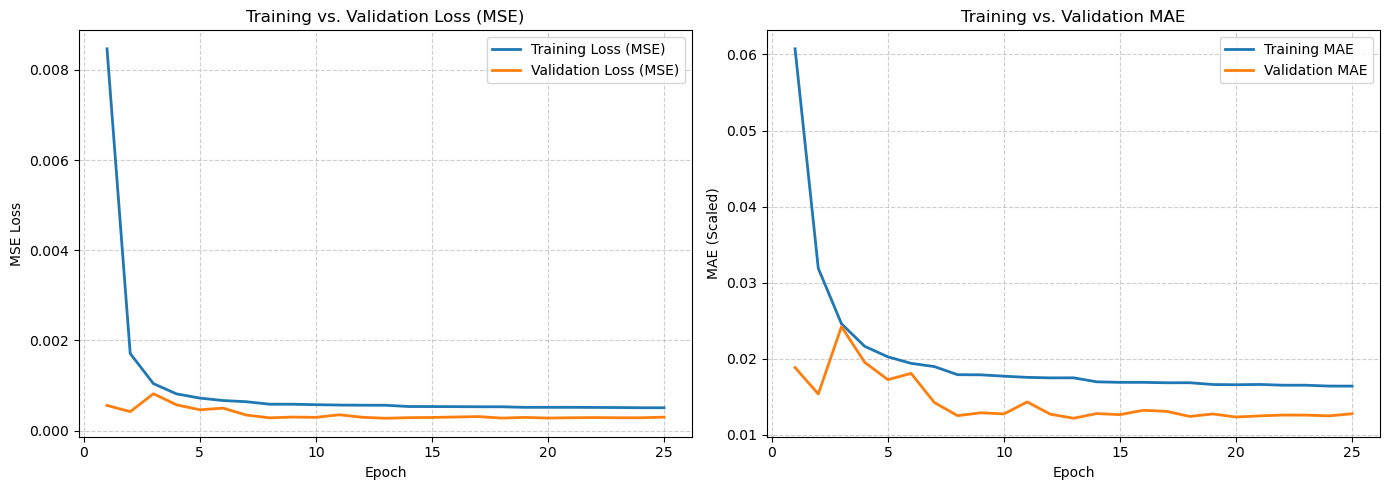

In [6]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_mae = history.history['mae']
val_mae = history.history['val_mae']
epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))

# MSE Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, label='Training Loss (MSE)', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss (MSE)', linewidth=2)
plt.title('Training vs. Validation Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# MAE Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_mae, label='Training MAE', linewidth=2)
plt.plot(epochs_range, val_mae, label='Validation MAE', linewidth=2)
plt.title('Training vs. Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE (Scaled)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 970us/step
       TEST SET EVALUATION METRICS
RMSE (Root Mean Squared Error) : 1.0047 °C
MAE  (Mean Absolute Error)     : 0.7234 °C
R² Score                       : 0.9882


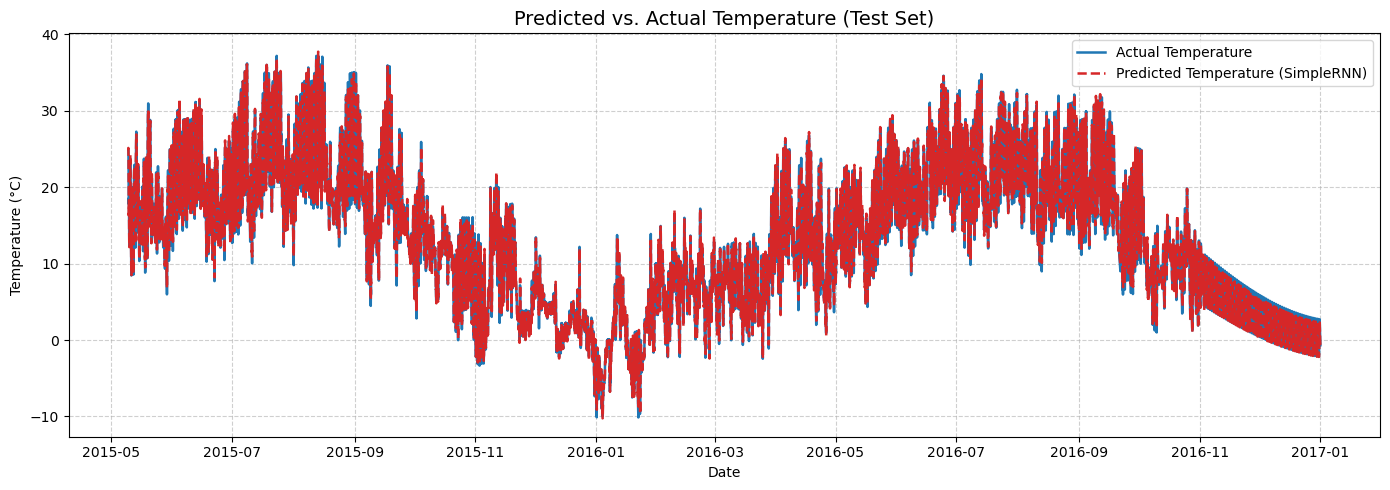

In [7]:
# 1. Generate predictions on the test set
y_pred_scaled = model.predict(X_test)

# Helper function to inverse-transform only the temperature column (column 0)
def inverse_transform_temp(scaled_temp_array, scaler_obj, n_features):
    dummy = np.zeros((len(scaled_temp_array), n_features))
    dummy[:, 0] = scaled_temp_array.flatten()
    return scaler_obj.inverse_transform(dummy)[:, 0]

# Convert scaled values back to original temperature units (°C)
y_test_actual = inverse_transform_temp(y_test, scaler, num_features)
y_test_pred = inverse_transform_temp(y_pred_scaled, scaler, num_features)

# 2. Calculate RMSE, MAE, and R² Score
rmse = np.sqrt(mean_squared_error(y_test_actual, y_test_pred))
mae = mean_absolute_error(y_test_actual, y_test_pred)
r2 = r2_score(y_test_actual, y_test_pred)

print("=" * 45)
print("       TEST SET EVALUATION METRICS")
print("=" * 45)
print(f"RMSE (Root Mean Squared Error) : {rmse:.4f} °C")
print(f"MAE  (Mean Absolute Error)     : {mae:.4f} °C")
print(f"R² Score                       : {r2:.4f}")
print("=" * 45)

# 3. Plot Predicted vs Actual Temperatures for the Test Period
test_dates = df_clean[date_col].iloc[val_end + SEQ_LENGTH:].values

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_test_actual, label='Actual Temperature', color='tab:blue', linewidth=1.8)
plt.plot(test_dates, y_test_pred, label='Predicted Temperature (SimpleRNN)', color='tab:red', linestyle='--', linewidth=1.8)
plt.title('Predicted vs. Actual Temperature (Test Set)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


--- Next 7 Days Temperature Forecast ---


,Date,Forecasted_Temperature (°C)
0,2017-01-01 23:00:00+01:00,-0.93
1,2017-01-02 23:00:00+01:00,-0.79
2,2017-01-03 23:00:00+01:00,-0.91
3,2017-01-04 23:00:00+01:00,-0.97
4,2017-01-05 23:00:00+01:00,-0.99
5,2017-01-06 23:00:00+01:00,-1.05
6,2017-01-07 23:00:00+01:00,-1.02


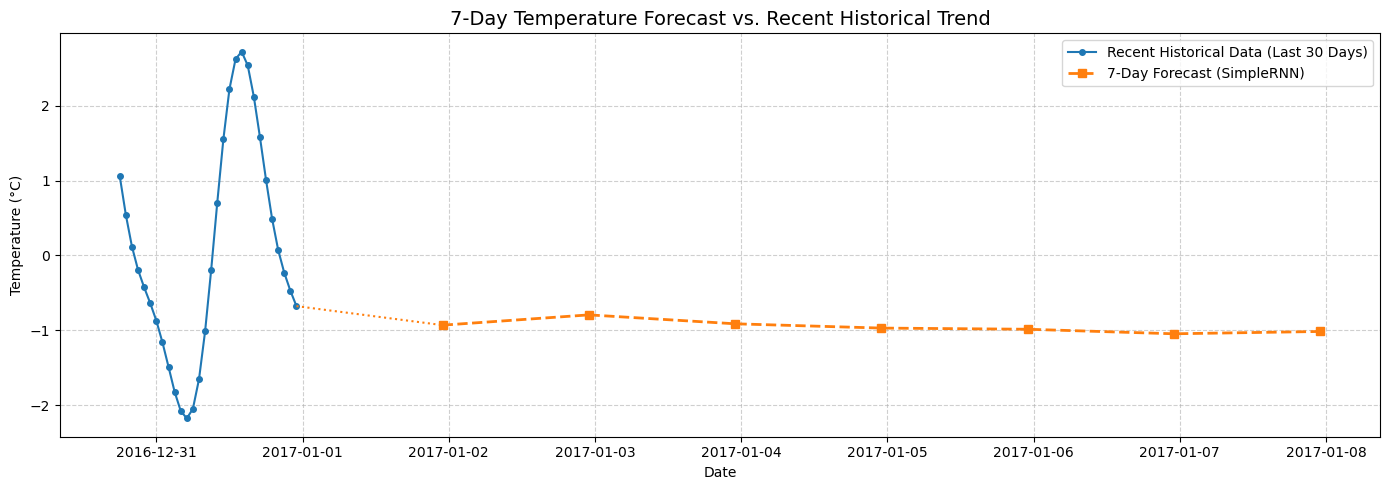

In [8]:
# 1. Take the final SEQ_LENGTH days from the scaled dataset as the starting window
current_window = test_scaled[-SEQ_LENGTH:].copy()  # Shape: (SEQ_LENGTH, num_features)
future_preds_scaled = []

# Use the mean of the last 7 days for auxiliary features (humidity, wind speed, etc.)
recent_aux_features = np.mean(test_scaled[-7:, 1:], axis=0)

# 2. Recursively forecast 7 days ahead
FORECAST_DAYS = 7

for _ in range(FORECAST_DAYS):
    # Reshape window to (1, SEQ_LENGTH, num_features) for model prediction
    input_seq = current_window.reshape(1, SEQ_LENGTH, num_features)
    next_temp_scaled = model.predict(input_seq, verbose=0)[0, 0]
    future_preds_scaled.append(next_temp_scaled)
    
    # Construct next day's feature vector: [predicted_temp, auxiliary_features...]
    next_day_features = np.concatenate(([next_temp_scaled], recent_aux_features))
    
    # Slide the window forward by dropping the oldest day and appending the new day
    current_window = np.vstack([current_window[1:], next_day_features])

# 3. Inverse-transform the 7-day forecast back to °C
future_temps = inverse_transform_temp(np.array(future_preds_scaled), scaler, num_features)

# Generate future dates
last_date = df_clean[date_col].iloc[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=FORECAST_DAYS)

# Print 7-Day Forecast Table
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecasted_Temperature (°C)': np.round(future_temps, 2)
})
print("\n--- Next 7 Days Temperature Forecast ---")
display(forecast_df)

# 4. Visualize 7-Day Forecast vs. Recent 30 Days of Historical Data
RECENT_DAYS = 30
recent_dates = df_clean[date_col].iloc[-RECENT_DAYS:]
recent_temps = df_clean[temp_col].iloc[-RECENT_DAYS:]

plt.figure(figsize=(14, 5))
plt.plot(recent_dates, recent_temps, label=f'Recent Historical Data (Last {RECENT_DAYS} Days)', color='tab:blue', marker='o', markersize=4)
plt.plot(future_dates, future_temps, label='7-Day Forecast (SimpleRNN)', color='tab:orange', marker='s', markersize=6, linestyle='--', linewidth=2)

# Connect the last historical point to the first forecasted point visually
plt.plot([recent_dates.iloc[-1], future_dates[0]], [recent_temps.iloc[-1], future_temps[0]], color='tab:orange', linestyle=':', linewidth=1.5)

plt.title('7-Day Temperature Forecast vs. Recent Historical Trend', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()